## 1. The task

Every graph in FRANKENSTEIN is one molecule. The nodes are atoms and the edges are chemical bonds. The molecules come from a mutagenicity dataset, but each atom's chemical symbol was replaced by the pixel intensities of an MNIST digit image, a 780-dimensional vector. So the model cannot read the atom type directly; it has to recognise it from a noisy picture.

For a molecule $G=(V,E,X)$ we predict one label $y\in\{0,1\}$ for the whole graph, mutagenic or non-mutagenic. This is graph classification.

The model is a Graph Isomorphism Network (GIN). Where a GCN averages over neighbours, a GIN sums them and passes the sum through a small MLP, so it can count how many neighbours of each kind an atom has. We look at the data, train a plain GIN, tune it on the validation split, and finish with three short analyses of the tuned model.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. Every run uses mini-batches of `batch_size` graphs.

The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`, that were never used for selection. The analyses use the first five of them, `abl_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 20, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds = final_seeds[:5]

## 3. Load FRANKENSTEIN

FRANKENSTEIN is one of the TU Dortmund benchmark datasets, and PyG downloads it with `TUDataset`.

Its node features are continuous attributes, not discrete labels, and `TUDataset` drops continuous attributes unless we pass `use_node_attr=True`. Without it every node would get an empty feature vector.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the notebook output. PyG warns on every max-pooling call that an optional package would make it faster; we silence just that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import TUDataset
warnings.filterwarnings('ignore', message='.*can be accelerated via')

dataset = TUDataset('/tmp/tud', 'FRANKENSTEIN', use_node_attr=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("graphs =", len(dataset), "   classes =", dataset.num_classes)
print("node features =", dataset.num_features, "   device =", device)

Processing...


graphs = 4337    classes = 2
node features = 780    device = cuda


Done!


## 4. One molecule

A graph is stored as node features `x` of shape $|V|\times780$, an edge list `edge_index` of shape $2\times|E|$, and a label `y`.

In [4]:
g = dataset[0]
print(g)
print("first edges:", g.edge_index[:, :8].tolist())
print("label:", g.y.item())

Data(edge_index=[2, 56], x=[25, 780], y=[1])
first edges: [[0, 0, 0, 1, 1, 1, 2, 2], [1, 2, 3, 0, 4, 5, 0, 6]]
label: 1


## 5. Check the graphs and the features

A GIN needs every bond stored in both directions, otherwise messages flow only one way. We check that, count graphs with isolated atoms, and look at the range of the features.

In [5]:
graphs = list(dataset)
X = torch.cat([g.x for g in graphs])
print("undirected graphs:", sum(g.is_undirected() for g in graphs), "of", len(graphs))
print("graphs with an isolated atom:", sum(g.has_isolated_nodes() for g in graphs))
print("feature range:", round(X.min().item(), 3), "to", round(X.max().item(), 3))
print("share of zero entries:", round((X == 0).float().mean().item(), 3))

undirected graphs: 4337 of 4337
graphs with an isolated atom: 209
feature range: 0.0 to 1.0
share of zero entries: 0.858


## 6. Split into train, validation and test

We use the same stratified 80/10/10 split as the other models, rebuilt from the same random state, so every model is scored on exactly the same test graphs.

The validation split chooses hyperparameters and the stopping epoch. The test split is used only to report results.

In [6]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

y = np.array([g.y.item() for g in graphs])
train_idx, rest = train_test_split(np.arange(len(y)), train_size=0.8, stratify=y, random_state=0)
val_idx, test_idx = train_test_split(rest, train_size=0.5, stratify=y[rest], random_state=0)

train_set, val_set, test_set = [[graphs[i] for i in idx] for idx in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  class 0 =", (yy == 0).sum(), "  class 1 =", (yy == 1).sum())

train   graphs = 3469   class 0 = 1549   class 1 = 1920
val   graphs = 434   class 0 = 193   class 1 = 241
test   graphs = 434   class 0 = 194   class 1 = 240


## 7. Class balance and molecule size

If both classes are about equally frequent, accuracy is a fair primary metric. We still report macro-F1 and ROC-AUC next to it.

In [7]:
counts = pd.DataFrame(dict(y=y, nodes=[g.num_nodes for g in graphs], edges=[g.num_edges // 2 for g in graphs]))
print(counts.groupby('y')[['nodes', 'edges']].describe().round(1).T)

y                 0       1
nodes count  1936.0  2401.0
      mean     16.4    17.3
      std      11.1     9.9
      min       2.0     2.0
      25%      10.0    12.0
      50%      14.0    17.0
      75%      20.0    21.0
      max     214.0   197.0
edges count  1936.0  2401.0
      mean     16.9    18.6
      std      12.2    11.1
      min       1.0     1.0
      25%       9.0    12.0
      50%      14.0    18.0
      75%      22.0    23.0
      max     217.0   206.0


## 8. How far does size alone go?

Two reference points for every GIN number below:

- always predicting the larger class, which needs no input at all;
- a logistic regression on $\log|V|$, the number of atoms, fitted on the training graphs. It tells us how much of the label is explained by size alone.

In [8]:
from sklearn.linear_model import LogisticRegression
logn = lambda d: np.log([[g.num_nodes] for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
print("test accuracy, always the larger class:", round(max(np.mean(y_test == 0), np.mean(y_test == 1)), 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))

test accuracy, always the larger class: 0.553
test accuracy from log|V| alone:       0.576


## 9. The GIN layer

One GIN layer updates every node from itself and its neighbours:

$h_i'=\text{MLP}\Big((1+\epsilon)\,h_i+\sum_{j\in N(i)}h_j\Big)$

Two things differ from a GCN:

- **Sum instead of average.** An atom with three carbon neighbours gets a different sum than an atom with one, while their averages would be the same. So a GIN can count.
- **An MLP instead of one linear map.** The MLP can map different neighbourhood sums to different outputs.

Xu et al. (2019) show that this makes GIN as powerful as the Weisfeiler-Lehman graph isomorphism test, the most a GNN of this kind can be. We use $\epsilon=0$, the GIN-0 variant from the paper.

A single layer maps every atom's 780 features to a new width.

In [9]:
from torch_geometric.nn import GINConv, MLP
conv = GINConv(MLP([dataset.num_features, 16, 16]))
print("one layer:", tuple(g.x.shape), "->", tuple(conv(g.x, g.edge_index).shape))

one layer: (25, 780) -> (25, 16)


## 10. From atoms to one graph vector

After $L$ layers each atom has seen its $L$-hop neighbourhood. PyG's `GIN` stacks $L$ such layers, each with its own two-layer MLP, with ReLU, dropout and, if `bn=True`, batch norm in between.

The first layer sums raw pixel vectors, so it sees a blend of several digit images. With `encode=True`, a small MLP first turns each atom's 780 pixels into `hidden` features on its own, before any message passing. The search decides whether this helps.

A readout then pools the atom embeddings into one vector per molecule, $h_G=\text{READOUT}\{h_v^{(L)}:v\in V\}$, with the mean, the max or the sum. An MLP maps $h_G$ to two logits, one per class.

`embed` returns $h_G$; we use it later for the t-SNE plot. Training settings stored in the same dictionary, such as the learning rate, are ignored by the model.

In [10]:
import torch.nn.functional as F
from torch_geometric.nn import GIN, global_mean_pool, global_max_pool, global_add_pool

pools = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=4, dropout=0.5, pool='add', bn=True, encode=False, **_):
        super().__init__()
        self.atom = MLP([dataset.num_features, hidden, hidden], norm=None) if encode else torch.nn.Identity()
        self.gnn = GIN(hidden if encode else dataset.num_features, hidden, layers, dropout=dropout, norm='batch_norm' if bn else None)
        self.pool = pools[pool]
        self.head = MLP([hidden, hidden, 2], dropout=dropout, norm=None)

    def embed(self, x, edge_index, batch):
        return self.pool(self.gnn(self.atom(x), edge_index).relu(), batch)

    def forward(self, x, edge_index, batch):
        return self.head(self.embed(x, edge_index, batch))

## 11. Train with early stopping on validation accuracy

We minimise cross-entropy with Adam on mini-batches of training graphs. After every epoch we measure validation accuracy, keep the best weights so far, and stop once it has not improved for `patience` epochs. The test split is never used here.

The validation and test graphs never change, so we batch them once and keep them on the GPU. `predict` returns $P(y=1\mid G)$ for every graph, and `scores` turns those probabilities into accuracy, macro-F1 and ROC-AUC.

In [11]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=512):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

@torch.no_grad()
def predict(model, bs):
    model.eval()
    return torch.cat([model(b.x, b.edge_index, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait = -1, 0
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.batch), b.y).backward()
            opt.step()
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

val_b, test_b = batches(val_set), batches(test_set)

## 12. A plain GIN baseline

Before tuning anything we train the configuration Xu et al. (2019) used for their bioinformatics datasets: four GIN layers of width 32, batch norm, sum readout, dropout $0.5$, learning rate $0.01$ and no weight decay. We leave out their learning-rate decay and their readout over every layer, so the baseline uses the same training loop and readout as our other models.

It is trained on the ten final seeds and we report test metrics as mean and standard deviation.

In [12]:
baseline = dict(hidden=32, layers=4, dropout=0.5, pool='add', bn=True, encode=False, lr=0.01, wd=0.0)
base = pd.DataFrame([scores(y_test, predict(fit(baseline, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.6412  0.6380  0.6954
std   0.0163  0.0166  0.0175


## 13. The search space

We tune eight hyperparameters. Depth and width set the capacity; dropout and weight decay regularise; the readout decides how the atom embeddings become one graph vector; batch norm and the learning rate affect the optimisation; `encode` decides whether each atom is encoded on its own first.

The full grid is too large to run, so we draw `n_trials` configurations uniformly at random (Bergstra and Bengio, 2012).

In [13]:
import random
space = dict(hidden=[32, 64, 128, 256], layers=[1, 2, 3, 4], dropout=[0.0, 0.2, 0.5], pool=['mean', 'max', 'add'],
             bn=[False, True], encode=[False, True], lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4, 1e-3])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")

20 of 6912 configurations


## 14. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. Averaging over seeds matters because one validation graph moves accuracy by about $0.23\%$.

In [14]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.6874 ± 0.0060  (132s)  {'hidden': 256, 'layers': 4, 'dropout': 0.0, 'pool': 'max', 'bn': True, 'encode': True, 'lr': 0.003, 'wd': 0.001}
 1  val = 0.6498 ± 0.0065  (60s)  {'hidden': 128, 'layers': 2, 'dropout': 0.5, 'pool': 'mean', 'bn': True, 'encode': False, 'lr': 0.001, 'wd': 0.0001}
 2  val = 0.6736 ± 0.0047  (162s)  {'hidden': 64, 'layers': 3, 'dropout': 0.0, 'pool': 'add', 'bn': False, 'encode': True, 'lr': 0.003, 'wd': 0.0}
 3  val = 0.6551 ± 0.0142  (157s)  {'hidden': 128, 'layers': 4, 'dropout': 0.2, 'pool': 'add', 'bn': False, 'encode': True, 'lr': 0.003, 'wd': 0.0001}
 4  val = 0.6682 ± 0.0086  (78s)  {'hidden': 32, 'layers': 1, 'dropout': 0.0, 'pool': 'add', 'bn': True, 'encode': False, 'lr': 0.01, 'wd': 0.001}
 5  val = 0.5783 ± 0.0326  (57s)  {'hidden': 128, 'layers': 2, 'dropout': 0.5, 'pool': 'max', 'bn': False, 'encode': False, 'lr': 0.01, 'wd': 1e-05}
 6  val = 0.6152 ± 0.0019  (79s)  {'hidden': 64, 'layers': 2, 'dropout': 0.5, 'pool': 'max', 'bn': False, 

## 15. The best configuration

We rank by mean validation accuracy and keep the top configuration.

Each panel below shows every trial's validation accuracy against one hyperparameter. A panel where the values separate cleanly marks a choice that matters; a flat one marks a choice that does not.

    hidden  layers  dropout  pool     bn  encode     lr      wd     val  val_std
8      128       4      0.0   add   True    True  0.010  0.0000  0.7166   0.0147
11      64       2      0.5   add   True    True  0.003  0.0010  0.6966   0.0115
0      256       4      0.0   max   True    True  0.003  0.0010  0.6874   0.0060
19      32       4      0.0   add  False    True  0.001  0.0001  0.6774   0.0198
2       64       3      0.0   add  False    True  0.003  0.0000  0.6736   0.0047
18     128       1      0.0  mean   True    True  0.003  0.0000  0.6690   0.0104
4       32       1      0.0   add   True   False  0.010  0.0010  0.6682   0.0086
13      64       2      0.0   add   True   False  0.010  0.0000  0.6682   0.0068
3      128       4      0.2   add  False    True  0.003  0.0001  0.6551   0.0142
9      128       2      0.0  mean  False    True  0.003  0.0000  0.6505   0.0089

best: {'hidden': 128, 'layers': 4, 'dropout': 0.0, 'pool': 'add', 'bn': True, 'encode': True, 'lr': 0.01, 'w

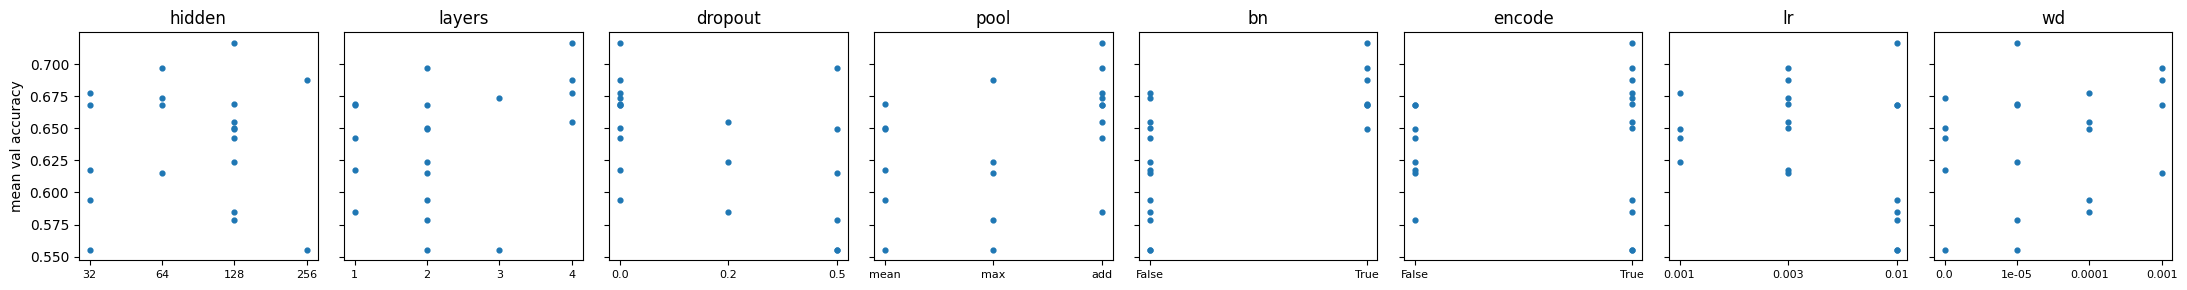

In [15]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = trials[search.index[0]]
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(22, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('gin_search.png', dpi=150); plt.show()

## 16. Test the tuned GIN on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the test graphs. The spread over seeds shows how much of any difference is noise.

In [16]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'baseline': base.mean(), 'baseline std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

     baseline  baseline std   tuned  tuned std
acc    0.6412        0.0163  0.6876     0.0204
f1     0.6380        0.0166  0.6835     0.0236
auc    0.6954        0.0175  0.7389     0.0230


## 17. The model we analyse

The analyses that need a single model use the run with the highest validation accuracy among the ten. Picking the highest test accuracy instead would be peeking at the test set.

Its confusion matrix shows whether the errors fall mostly on one class.

seed 108   val acc = 0.7143   test: {'acc': 0.6982, 'f1': 0.6959, 'auc': 0.7716}


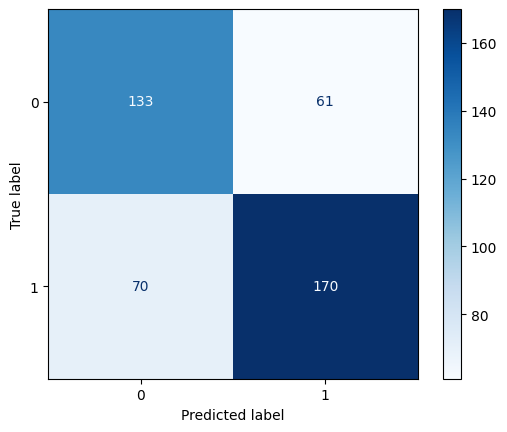

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5)).plot(cmap='Blues')
plt.savefig('gin_confusion.png', dpi=150); plt.show()

## 18. Ablation: what does the GIN need?

An ablation removes or changes one ingredient and retrains with the tuned hyperparameters on the seeds in `abl_seeds`. Train, validation and test graphs are changed in the same way.

- **No edges.** Every bond is deleted, so each atom sees only itself and the GIN becomes a per-atom MLP followed by the readout. Only the bag of atoms is left.
- **Constant features.** Every $x_v$ becomes a vector of ones, so the model cannot tell atoms apart and only the shape of the molecule is left.
- **Atom encoder switched.** We flip `encode`: if the tuned model uses the atom encoder we remove it, otherwise we add it. This shows whether encoding each atom on its own before message passing helps.

`Δ acc` is the change against the tuned GIN on the same seeds.

In [18]:
def no_edges(g): g.edge_index = g.edge_index[:, :0]; return g
def ones(g):     g.x = torch.ones_like(g.x); return g

def variant(f):
    return [f(g.clone()) for g in train_set], batches([f(g.clone()) for g in val_set]), batches([f(g.clone()) for g in test_set])

def run(c, tr, va, te):
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in abl_seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

abl = {'tuned GIN': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges', no_edges), ('constant features', ones)]:
    abl[name] = run(best, *variant(f))
abl['atom encoder ' + ('off' if best['encode'] else 'on')] = run(dict(best, encode=not best['encode']), train_set, val_b, test_b)
print(table(abl))

                      acc      f1     auc  acc std   Δ acc
tuned GIN          0.6779  0.6724  0.7258   0.0128  0.0000
no edges           0.5636  0.5300  0.5525   0.0285 -0.1143
constant features  0.6664  0.6631  0.7232   0.0266 -0.0115
atom encoder off   0.6516  0.6477  0.6967   0.0218 -0.0263


## 19. Depth

A GCN averages an atom with its neighbours, and repeated averaging pulls all embeddings of a graph towards the same vector (over-smoothing). A GIN sums instead and passes the result through an MLP, so it should suffer less from this, although deeper models are still harder to train. The molecules are small, so a few layers already cover most of a graph.

We train the tuned configuration with 1, 2, 4 and 8 layers.

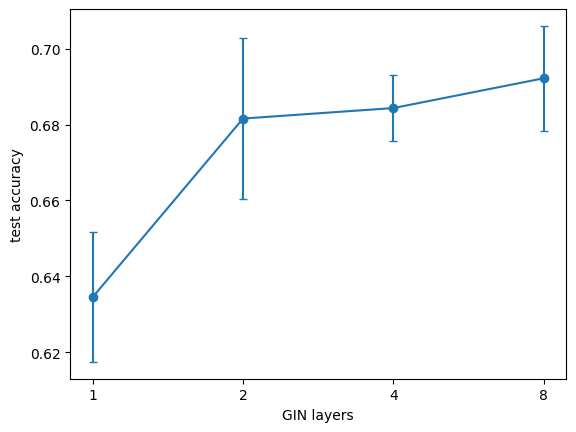

In [19]:
Ls = [1, 2, 4, 8]
depth = {L: run(dict(best, layers=L), train_set, val_b, test_b) for L in Ls}
plt.errorbar(Ls, [depth[L].acc.mean() for L in Ls], [depth[L].acc.std() for L in Ls], marker='o', capsize=3)
plt.xscale('log', base=2); plt.xticks(Ls, Ls)
plt.xlabel("GIN layers"); plt.ylabel("test accuracy")
plt.savefig('gin_depth.png', dpi=150); plt.show()

## 20. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per molecule. t-SNE maps these vectors to 2D while keeping near neighbours near.

On the left is the input itself, the mean of each molecule's raw atom features. On the right is the tuned GIN's embedding. Colour is the true class, and crosses are graphs the model gets wrong.

The silhouette score, computed in the original space and not in 2D, measures class separation on a scale from $-1$ to $1$.

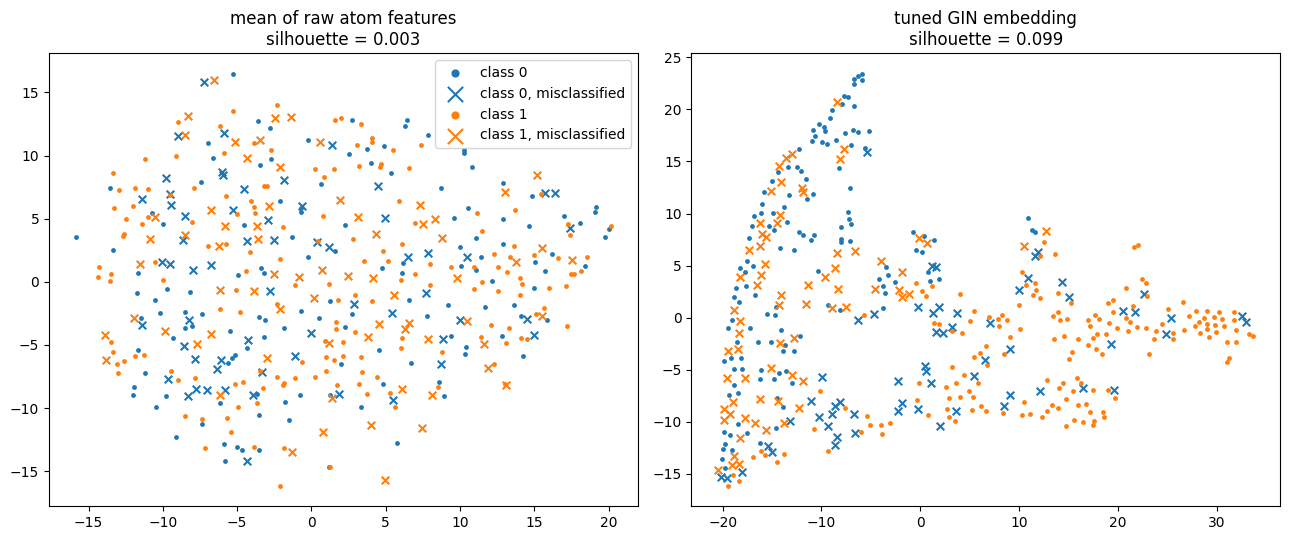

In [20]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw atom features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GIN embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=6, c=col, label=f'class {c}')
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'class {c}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('gin_tsne.png', dpi=150); plt.show()

## 21. Save the results

Everything needed to compare the GIN with the other models goes into one JSON file, together with the split indices. The per-run test probabilities are saved too, so the models' errors can later be compared graph by graph.

In [21]:
import json
res = dict(model='GIN', dataset='FRANKENSTEIN (TUDataset, 780 node attributes)',
           split=dict(rule='stratified 80/10/10, random_state=0', train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist()),
           size_only_acc=size_acc, best_config=best,
           baseline=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(), tuned_runs=tuned.to_dict('list'),
           ablation=table(abl).to_dict('index'),
           depth={f'layers={L}': [v.acc.mean(), v.acc.std()] for L, v in depth.items()},
           silhouette=sil, minutes=(time.time() - t0) / 60)
json.dump(res, open('gin_frankenstein_results.json', 'w'), indent=1, default=float)
np.save('gin_frankenstein_test_probs.npy', P)
search.to_csv('gin_frankenstein_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, baseline, best_config, dataset, depth, minutes, model, silhouette, size_only_acc, split, tuned, tuned_runs
total run time: 68 minutes


## 22. Conclusion

The whole notebook ran in 68 minutes on a Kaggle T4.

**Results.** Always predicting the larger class gives 0.553 test accuracy, and the number of atoms alone gives 0.576. The plain GIN from the paper learns straight away: 0.641 ± 0.016 accuracy, macro-F1 0.638 ± 0.017 and ROC-AUC 0.695 ± 0.018 over ten seeds, already above the tuned GCN. The tuned GIN reaches 0.688 ± 0.020 accuracy, macro-F1 0.684 ± 0.024 and ROC-AUC 0.739 ± 0.023. Tuning adds about five points, more than twice the spread over seeds. The chosen configuration has 4 layers of width 128, the atom encoder, batch norm, sum readout, no dropout, learning rate $10^{-2}$ and weight decay $10^{-5}$.

**Search.** The six best trials all use the atom encoder, and four of the five best use the sum readout. The five worst trials (0.555 to 0.595) are exactly the five that combine learning rate $10^{-2}$ with no batch norm; two of them never leave the larger class. With batch norm the same learning rate works well and gives the best trial. The best validation accuracy (0.717) is above the test accuracy (0.688): with 20 trials and only 434 validation graphs, the top trial is partly lucky.

**Errors.** The analysed run (seed 108, test accuracy 0.698) gets 170 of 240 class-1 molecules right (71%) and 133 of 194 class-0 molecules (69%). Like the Graph Transformer and unlike the GCN, it does not lean towards the larger class.

**What the GIN uses.** Over five seeds the tuned GIN scores 0.678. Removing the bonds lowers it by 0.114 to 0.564, below size alone, so the GIN depends mainly on the bonds. Constant features lower it by only 0.012 to 0.666, less than one standard deviation: almost all of its accuracy comes from the shape of the molecule, and that shape alone already beats the full tuned GCN (0.603). Switching the atom encoder off lowers it by 0.026 to 0.652, about one standard deviation; together with the search, this suggests that encoding each atom on its own first helps a little.

**Depth.** Accuracy rises from 0.635 with 1 layer to 0.682 with 2, 0.684 with 4 and 0.692 with 8 layers. The GCN fell to 0.574 at 8 layers, but the GIN shows no sign of over-smoothing, as expected from a layer that sums instead of averaging. One layer is clearly too few; from 2 layers on the error bars overlap.

**Visualisation.** The silhouette score rises from 0.003 for the raw features to 0.099 for the GIN embedding, close to the Graph Transformer's 0.101 and far above the GCN's 0.003. In the t-SNE plot the embedding forms long branches: class 1 fills most of the right-hand branch and class 0 most of the upper-left one, while the lower-left region mixes both classes and holds many of the errors.

**GCN vs GIN vs Graph Transformer.**

| | GCN | GIN | GPS |
|---|---|---|---|
| test accuracy (tuned) | 0.603 ± 0.014 | 0.688 ± 0.020 | 0.742 ± 0.018 |
| macro-F1 (tuned) | 0.590 ± 0.022 | 0.684 ± 0.024 | 0.738 ± 0.019 |
| ROC-AUC (tuned) | 0.633 ± 0.011 | 0.739 ± 0.023 | 0.804 ± 0.009 |
| test accuracy (untuned baseline) | 0.553 | 0.641 | 0.731 |
| accuracy lost without bonds | 0.016 | 0.114 | 0.184 |
| accuracy lost with constant features | 0.039 | 0.012 | 0.044 |
| accuracy with 8 layers | 0.574 | 0.692 | 0.738 |
| silhouette of the embedding | 0.003 | 0.099 | 0.101 |
| run time on a T4 | 52 min | 68 min | 121 min |

The GIN sits between the other two: about nine points above the GCN and five below the Graph Transformer. Replacing the GCN's average with a sum and an MLP is the bigger step: it lets the model count neighbours and read the structure of the molecule, which the GCN barely used. The Graph Transformer adds random-walk encodings and attention on top of a GIN layer. Without its encodings it scored 0.667 on the same five seeds, about the same as the tuned GIN (0.678), so the ring information they carry is likely most of what it adds.